# Kripto Takas Platformunda Güven Ağı
**Araştırma sorusu:** Güvensizlik (negatif) kenarları belirli kümelerde toplanıyor mu? Ağ yapısal olarak "dengeli" mi?

Veri: SNAP `soc-sign-bitcoin-otc`. Ağ `scripts/02_ag_kur.py` ile kurulur. Bu defter yukarıdan aşağı çalıştırıldığında
tüm sayıları, tabloları ve şekilleri yeniden üretir (`SEED = 42`).

In [1]:
import json
import random
import warnings
from collections import Counter
from itertools import combinations
from pathlib import Path

import igraph as ig
import leidenalg
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import powerlaw
from scipy.stats import spearmanr
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
MAVI, TURUNCU, GRI = "#2f6db5", "#d9822b", "#8a8f98"
ozet = {}

## 1. Veriyi yükle ve ağı kur

In [2]:
kenar = pd.read_csv("data/processed/kenarlar.csv")
kenar["yil"] = kenar["tarih"].str[:4].astype(int)
G = nx.from_pandas_edgelist(kenar, "kaynak", "hedef", ["puan", "isaret", "yil"], create_using=nx.DiGraph)

# Yönsüz, işaretsiz görünüm (kümelenme, yol, topluluk için)
U = G.to_undirected(as_view=False)

# Yönsüz, işaretli görünüm: iki yönlü puan varsa işaret = puanların toplamının işareti.
cift = {}
for u, v, d in G.edges(data=True):
    k = tuple(sorted((u, v)))
    cift.setdefault(k, []).append(d["puan"])
S = nx.Graph()
celiski = 0
for (u, v), puanlar in cift.items():
    t = sum(puanlar)
    if t == 0:
        celiski += 1
        continue
    S.add_edge(u, v, isaret=1 if t > 0 else -1)

n, m = G.number_of_nodes(), G.number_of_edges()
neg_oran = (kenar["isaret"] < 0).mean()
karsilikli = sum(1 for k, p in cift.items() if len(p) == 2)
ozet["temel"] = {
    "dugum": n, "kenar_yonlu": m, "kenar_yonsuz": U.number_of_edges(),
    "negatif_kenar_orani": round(float(neg_oran), 4),
    "karsilikli_cift": karsilikli, "karsilikli_oran": round(karsilikli / len(cift), 4),
    "celiskili_cift_atilan": celiski,
    "tarih_araligi": [kenar["tarih"].min(), kenar["tarih"].max()],
}
ozet["temel"]

{'dugum': 5881,
 'kenar_yonlu': 35592,
 'kenar_yonsuz': 21492,
 'negatif_kenar_orani': 0.1001,
 'karsilikli_cift': 14100,
 'karsilikli_oran': 0.6561,
 'celiskili_cift_atilan': 58,
 'tarih_araligi': ['2010-11-08', '2016-01-25']}

## 2. Temel ağ ölçüleri

In [3]:
yogunluk = nx.density(G)
wcc = list(nx.weakly_connected_components(G))
scc = list(nx.strongly_connected_components(G))
lcc_nodes = max(wcc, key=len)

# igraph ile hızlı ve kesin yol hesabı (en büyük zayıf bileşen, yönsüz)
def to_ig(nxg):
    names = list(nxg.nodes())
    idx = {v: i for i, v in enumerate(names)}
    g = ig.Graph(n=len(names), edges=[(idx[u], idx[v]) for u, v in nxg.edges()], directed=nxg.is_directed())
    g.vs["name"] = names
    return g

UL = U.subgraph(lcc_nodes).copy()
gU = to_ig(UL)
ort_yol = gU.average_path_length(directed=False)
cap = gU.diameter(directed=False)
kum_ort = gU.transitivity_avglocal_undirected(mode="zero")
kum_global = gU.transitivity_undirected()
asort = nx.degree_assortativity_coefficient(U)
asort_in_out = nx.degree_assortativity_coefficient(G, x="out", y="in")

ozet["olculer"] = {
    "yogunluk": yogunluk, "zayif_bilesen": len(wcc), "en_buyuk_zayif_bilesen": len(lcc_nodes),
    "guclu_bilesen": len(scc), "en_buyuk_guclu_bilesen": len(max(scc, key=len)),
    "ort_en_kisa_yol": ort_yol, "cap": cap, "ort_kumelenme": kum_ort, "global_kumelenme": kum_global,
    "derece_benzesimi": asort, "derece_benzesimi_out_in": asort_in_out,
}
pd.Series(ozet["olculer"]).round(5)

yogunluk                      0.00103
zayif_bilesen                 4.00000
en_buyuk_zayif_bilesen     5875.00000
guclu_bilesen              1144.00000
en_buyuk_guclu_bilesen     4709.00000
ort_en_kisa_yol               3.57109
cap                           9.00000
ort_kumelenme                 0.17769
global_kumelenme              0.05924
derece_benzesimi             -0.16483
derece_benzesimi_out_in      -0.16395
dtype: float64

## 3. Derece dağılımı ve kuvvet yasası testi

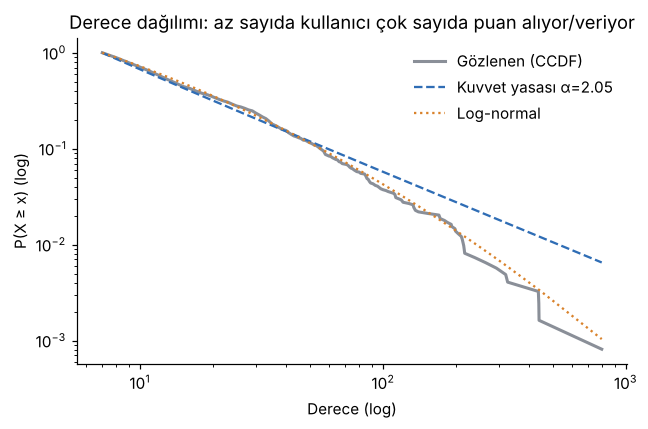

{'alpha': 2.0477570512666308,
 'xmin': 7,
 'kuyruktaki_dugum': 1230,
 'karsilastirma': {'lognormal': {'R': -3.5753326443454228,
   'p': 0.00034978287099115646},
  'exponential': {'R': 5.812554428204531, 'p': 6.152666944666248e-09},
  'truncated_power_law': {'R': -3.835387044380775,
   'p': 1.5822280152733015e-09}}}

In [4]:
derece = np.array([d for _, d in U.degree()])
fit = powerlaw.Fit(derece, discrete=True, verbose=False)
karsilastir = {}
for alt in ["lognormal", "exponential", "truncated_power_law"]:
    R, p = fit.distribution_compare("power_law", alt, normalized_ratio=True)
    karsilastir[alt] = {"R": float(R), "p": float(p)}
ozet["kuvvet_yasasi"] = {"alpha": float(fit.power_law.alpha), "xmin": int(fit.power_law.xmin),
                         "kuyruktaki_dugum": int((derece >= fit.power_law.xmin).sum()), "karsilastirma": karsilastir}

fig, ax = plt.subplots(figsize=(6, 4))
fit.plot_ccdf(ax=ax, color=GRI, linewidth=2, label="Gözlenen (CCDF)")
fit.power_law.plot_ccdf(ax=ax, color=MAVI, linestyle="--", label=f"Kuvvet yasası α={fit.power_law.alpha:.2f}")
fit.lognormal.plot_ccdf(ax=ax, color=TURUNCU, linestyle=":", label="Log-normal")
ax.set_xlabel("Derece (log)"); ax.set_ylabel("P(X ≥ x) (log)")
ax.set_title("Derece dağılımı: az sayıda kullanıcı çok sayıda puan alıyor/veriyor")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "derece_dagilimi.png", dpi=200); plt.show()
ozet["kuvvet_yasasi"]

`R > 0` kuvvet yasası lehine, `R < 0` alternatif lehinedir; `p < 0.05` ise fark anlamlıdır.

## 4. Merkeziyetler

In [5]:
gD = to_ig(G)
gD.es["puan"] = [G[u][v]["puan"] for u, v in G.edges()]
names = gD.vs["name"]
gUall = to_ig(U)
idxU = {v: i for i, v in enumerate(gUall.vs["name"])}

mer = pd.DataFrame(index=names)
mer["derece"] = gD.degree(mode="all")
mer["gelen"] = gD.degree(mode="in")
mer["betweenness"] = gD.betweenness(directed=True)
mer["betweenness"] /= (n - 1) * (n - 2)
clo = gUall.closeness(normalized=True)
mer["closeness"] = [clo[idxU[v]] for v in names]
mer["closeness"] = mer["closeness"].fillna(0)
mer["pagerank"] = gD.pagerank(directed=True)
eig = gUall.eigenvector_centrality(scale=True)
mer["eigenvector"] = [eig[idxU[v]] for v in names]

olcu = ["derece", "betweenness", "closeness", "pagerank", "eigenvector"]
ilk10 = {c: mer[c].nlargest(10).index.tolist() for c in olcu}
spear = mer[olcu].corr(method="spearman")
ozet["merkeziyet_spearman"] = spear.round(3).to_dict()
ozet["ilk10_ortak_pagerank_betweenness"] = len(set(ilk10["pagerank"]) & set(ilk10["betweenness"]))
mer.sort_values("pagerank", ascending=False).head(10).round(5)

,derece,gelen,betweenness,closeness,pagerank,eigenvector
K28a80ce,1298,535,0.14211,0.42792,0.01502,0.77418
K70e1713,818,412,0.06220,0.41088,0.01077,0.92808
K60ebdd2,715,311,0.04953,0.41137,0.00697,0.96819
Kb01c759,572,279,0.03878,0.40772,0.00675,0.82077
Kd04a7ad,448,216,0.03982,0.39344,0.00591,0.41646
Kfa86973,528,264,0.04814,0.43647,0.00537,1.00000
K9498d38,334,165,0.03231,0.38742,0.00508,0.37499
Kb20b6b6,441,226,0.04500,0.43347,0.00503,0.74655
Kfd58626,486,222,0.04190,0.40338,0.00476,0.71741
K070756d,405,203,0.01816,0.38242,0.00466,0.55511


In [6]:
spear.round(2)

,derece,betweenness,closeness,pagerank,eigenvector
derece,1.00,0.89,0.63,0.90,0.65
betweenness,0.89,1.00,0.59,0.83,0.59
closeness,0.63,0.59,1.00,0.49,0.97
pagerank,0.90,0.83,0.49,1.00,0.50
eigenvector,0.65,0.59,0.97,0.50,1.00


### 4.1 Pozitif ve negatif alt ağların ayrı merkeziyetleri (kişisel ileri yöntem)
Pozitif alt ağda PageRank "itibar", negatif alt ağda PageRank "toplanan güvensizlik" ölçüsüdür.

In [7]:
pos_e = [(u, v, d["puan"]) for u, v, d in G.edges(data=True) if d["puan"] > 0]
neg_e = [(u, v, -d["puan"]) for u, v, d in G.edges(data=True) if d["puan"] < 0]

def pr_alt(edges):
    g = nx.DiGraph(); g.add_nodes_from(G.nodes()); g.add_weighted_edges_from(edges)
    gi = to_ig(g); gi.es["weight"] = [g[u][v]["weight"] for u, v in g.edges()]
    pr = gi.pagerank(directed=True, weights="weight")
    return pd.Series(pr, index=gi.vs["name"]), g

pr_pos, Gpos = pr_alt(pos_e)
pr_neg, Gneg = pr_alt(neg_e)
mer["pr_pozitif"] = pr_pos
mer["pr_negatif"] = pr_neg
mer["gelen_pozitif"] = pd.Series(dict(Gpos.in_degree()))
mer["gelen_negatif"] = pd.Series(dict(Gneg.in_degree()))

aktif = mer[(mer["gelen_pozitif"] + mer["gelen_negatif"]) >= 5]
rho_pn, p_pn = spearmanr(aktif["pr_pozitif"], aktif["pr_negatif"])
ilk_pos = set(mer["pr_pozitif"].nlargest(20).index)
ilk_neg = set(mer["pr_negatif"].nlargest(20).index)
mer["neg_pay_gelen"] = mer["gelen_negatif"] / (mer["gelen_pozitif"] + mer["gelen_negatif"]).replace(0, np.nan)

ozet["pozitif_negatif"] = {
    "pozitif_kenar": len(pos_e), "negatif_kenar": len(neg_e),
    "spearman_pr_pos_neg_aktif": float(rho_pn), "p": float(p_pn), "aktif_dugum": int(len(aktif)),
    "ilk20_kesisim": len(ilk_pos & ilk_neg),
    "negatif_alanlarin_payi": float((mer["gelen_negatif"] > 0).mean()),
    "negatif_kenarlarin_yuzde_kaci_ilk_yuzde5": float(
        mer["gelen_negatif"].nlargest(int(0.05 * n)).sum() / len(neg_e)),
}
tab_neg = mer.sort_values("pr_negatif", ascending=False).head(10)[["gelen_pozitif", "gelen_negatif", "neg_pay_gelen", "pr_negatif", "pr_pozitif"]]
ozet["pozitif_negatif"]

{'pozitif_kenar': 32029,
 'negatif_kenar': 3563,
 'spearman_pr_pos_neg_aktif': -0.06121358514561295,
 'p': 0.018161210443180198,
 'aktif_dugum': 1489,
 'ilk20_kesisim': 4,
 'negatif_alanlarin_payi': 0.21322904267981635,
 'negatif_kenarlarin_yuzde_kaci_ilk_yuzde5': 0.636261577322481}

In [8]:
tab_neg.round(4)

,gelen_pozitif,gelen_negatif,neg_pay_gelen,pr_negatif,pr_pozitif
Ke7b43b2,6,75,0.9259,0.0051,0.0001
K578008e,66,26,0.2826,0.0038,0.0028
K60ebdd2,270,41,0.1318,0.0037,0.0075
Kfad0163,51,45,0.4688,0.0035,0.0012
K956ca86,6,4,0.4000,0.0033,0.0001
Kc609330,2,1,0.3333,0.0031,0.0001
Kc47bbe9,1,2,0.6667,0.0030,0.0000
Kb277636,62,20,0.2439,0.0029,0.0017
K4f95f76,12,6,0.3333,0.0028,0.0002
Kc32157d,9,36,0.8000,0.0025,0.0004


### 4.2 Kırılganlık: en merkezi hesaplar ağdan çıkarılırsa ne olur?
Betweenness'ın gerçek anlamını görmek için en yüksek betweenness'a sahip hesap (ve ilk 10) silinir; ana bileşen ve ortalama yol yeniden ölçülür.

In [9]:
def bilesen_ozeti(g):
    cc = g.connected_components()
    gc = cc.giant()
    return {"ana_bilesen": gc.vcount(), "bilesen_sayisi": len(cc), "ort_yol": gc.average_path_length()}

ilk_bt = mer["betweenness"].nlargest(10).index.tolist()
kirilganlik = {"once": bilesen_ozeti(gUall)}
h = gUall.copy(); h.delete_vertices([idxU[ilk_bt[0]]])
kirilganlik["en_merkezi_silinince"] = {"dugum": ilk_bt[0], **bilesen_ozeti(h)}
h = gUall.copy(); h.delete_vertices([idxU[v] for v in ilk_bt])
kirilganlik["ilk10_silinince"] = bilesen_ozeti(h)
ozet["kirilganlik"] = kirilganlik
pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "dugum"} for k, v in kirilganlik.items()}).T.round(3)

,ana_bilesen,bilesen_sayisi,ort_yol
once,5875.0,4.0,3.571
en_merkezi_silinince,5561.0,308.0,3.645
ilk10_silinince,5155.0,696.0,3.868


## 5. Yapısal denge (kişisel ileri yöntem)
Heider'in kuramına göre bir üçgen, üzerindeki negatif kenar sayısı **çift** ise dengelidir:
`+++` ("dostumun dostu dostumdur") ve `+−−` ("düşmanımın düşmanı dostumdur"). `++−` dengesizdir.
`−−−` güçlü dengeye göre dengesiz, Davis'in zayıf dengesine göre dengelidir.

In [10]:
s_nodes = list(S.nodes()); sidx = {v: i for i, v in enumerate(s_nodes)}
s_edges = list(S.edges()); eidx = {tuple(sorted((sidx[u], sidx[v]))): i for i, (u, v) in enumerate(s_edges)}
isaret = np.array([S[u][v]["isaret"] for u, v in s_edges])
adj = [set() for _ in s_nodes]
for u, v in s_edges:
    adj[sidx[u]].add(sidx[v]); adj[sidx[v]].add(sidx[u])
ucgen = []  # her üçgenin 3 kenar indeksi
for a in range(len(s_nodes)):
    for b in adj[a]:
        if b <= a: continue
        for c in adj[a] & adj[b]:
            if c <= b: continue
            ucgen.append((eidx[(a, b)], eidx[(a, c)], eidx[(b, c)]))
ucgen = np.array(ucgen)

def ucgen_tipleri(sgn):
    negs = (sgn[ucgen] < 0).sum(axis=1)
    return np.bincount(negs, minlength=4)  # 0:+++ 1:++- 2:+-- 3:---

tip = ucgen_tipleri(isaret)
T = tip.sum()
denge_guclu = (tip[0] + tip[2]) / T
denge_zayif = (tip[0] + tip[2] + tip[3]) / T

# Null model: üçgen yapısı sabit, işaretler kenarlar arasında 1000 kez karıştırılır.
rng = np.random.default_rng(SEED)
null_guclu, null_tip = [], []
for _ in range(1000):
    t = ucgen_tipleri(rng.permutation(isaret))
    null_guclu.append((t[0] + t[2]) / T); null_tip.append(t)
null_guclu = np.array(null_guclu); null_tip = np.array(null_tip)
z_denge = (denge_guclu - null_guclu.mean()) / null_guclu.std()
z_tip = (tip - null_tip.mean(axis=0)) / null_tip.std(axis=0)

ozet["denge"] = {
    "ucgen": int(T), "tipler": {"+++": int(tip[0]), "++-": int(tip[1]), "+--": int(tip[2]), "---": int(tip[3])},
    "guclu_denge_orani": float(denge_guclu), "zayif_denge_orani": float(denge_zayif),
    "null_guclu_ort": float(null_guclu.mean()), "null_guclu_std": float(null_guclu.std()),
    "z_guclu_denge": float(z_denge), "z_tip": dict(zip(["+++", "++-", "+--", "---"], map(float, z_tip))),
    "beklenen_tip": dict(zip(["+++", "++-", "+--", "---"], map(float, null_tip.mean(axis=0)))),
}
ozet["denge"]

{'ucgen': 32944,
 'tipler': {'+++': 23365, '++-': 3875, '+--': 5378, '---': 326},
 'guclu_denge_orani': 0.8724805730937348,
 'zayif_denge_orani': 0.8823761534725595,
 'null_guclu_ort': 0.675583292860612,
 'null_guclu_std': 0.006324340539629866,
 'z_guclu_denge': 31.133250810786713,
 'z_tip': {'+++': 10.015389629695823,
  '++-': -33.4261810940755,
  '+--': 36.10876170081578,
  '---': 16.511185733764624},
 'beklenen_tip': {'+++': 20433.428,
  '++-': 10582.53,
  '+--': 1822.988,
  '---': 105.054}}

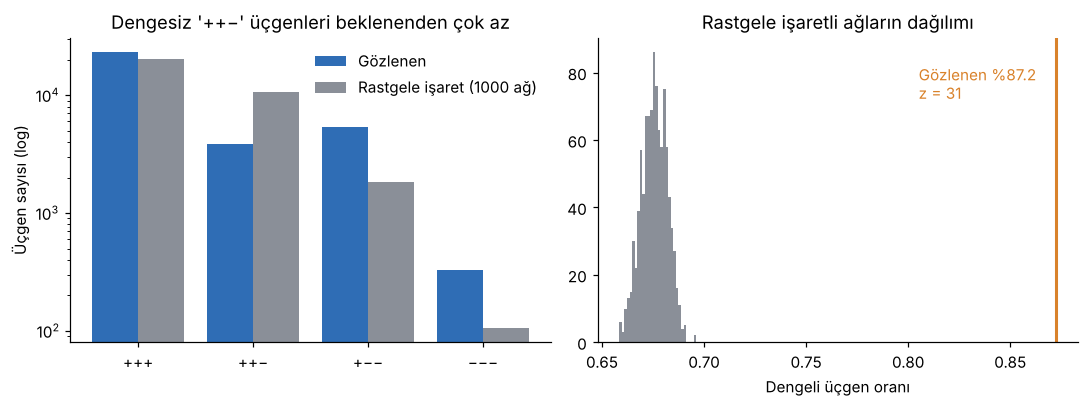

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
etiket = ["+++", "++−", "+−−", "−−−"]
x = np.arange(4)
ax.bar(x - 0.2, tip, 0.4, color=MAVI, label="Gözlenen")
ax.bar(x + 0.2, null_tip.mean(axis=0), 0.4, color=GRI, label="Rastgele işaret (1000 ağ)")
ax.set_xticks(x, etiket); ax.set_yscale("log"); ax.set_ylabel("Üçgen sayısı (log)")
ax.set_title("Dengesiz '++−' üçgenleri beklenenden çok az"); ax.legend(frameon=False)
ax = axes[1]
ax.hist(null_guclu, bins=30, color=GRI)
ax.axvline(denge_guclu, color=TURUNCU, lw=2)
ax.annotate(f"Gözlenen %{denge_guclu*100:.1f}\nz = {z_denge:.0f}", (denge_guclu, ax.get_ylim()[1] * 0.8),
            xytext=(-90, 0), textcoords="offset points", color=TURUNCU)
ax.set_xlabel("Dengeli üçgen oranı"); ax.set_title("Rastgele işaretli ağların dağılımı")
fig.tight_layout(); fig.savefig(FIG / "yapisal_denge.png", dpi=200); plt.show()

## 6. Topluluk tespiti: Louvain ve Leiden, 10 tohumla kararlılık

In [12]:
def louvain(g, seed):
    random.seed(seed)
    return g.community_multilevel(return_levels=False)

def leiden(g, seed):
    return leidenalg.find_partition(g, leidenalg.ModularityVertexPartition, seed=seed)

seeds = list(range(10))
lv = [louvain(gUall, s) for s in seeds]
ld = [leiden(gUall, s) for s in seeds]
lv_mem = [p.membership for p in lv]; ld_mem = [p.membership for p in ld]

def ciftler(mems, f):
    return [f(a, b) for a, b in combinations(mems, 2)]

kararlilik = {
    "louvain_modularite_ort": float(np.mean([gUall.modularity(m) for m in lv_mem])),
    "louvain_modularite_std": float(np.std([gUall.modularity(m) for m in lv_mem])),
    "leiden_modularite_ort": float(np.mean([gUall.modularity(m) for m in ld_mem])),
    "leiden_modularite_std": float(np.std([gUall.modularity(m) for m in ld_mem])),
    "louvain_topluluk_sayisi": [len(set(m)) for m in lv_mem],
    "leiden_topluluk_sayisi": [len(set(m)) for m in ld_mem],
    "louvain_nmi_ort": float(np.mean(ciftler(lv_mem, normalized_mutual_info_score))),
    "leiden_nmi_ort": float(np.mean(ciftler(ld_mem, normalized_mutual_info_score))),
    "louvain_ari_ort": float(np.mean(ciftler(lv_mem, adjusted_rand_score))),
    "leiden_ari_ort": float(np.mean(ciftler(ld_mem, adjusted_rand_score))),
    "louvain_leiden_nmi": float(np.mean([normalized_mutual_info_score(a, b) for a in lv_mem for b in ld_mem])),
}
ozet["topluluk"] = kararlilik
kararlilik

{'louvain_modularite_ort': 0.48891580258621586,
 'louvain_modularite_std': 0.0068289800120937,
 'leiden_modularite_ort': 0.4983236609987437,
 'leiden_modularite_std': 0.008634680302616821,
 'louvain_topluluk_sayisi': [17, 17, 19, 19, 25, 21, 21, 18, 18, 22],
 'leiden_topluluk_sayisi': [18, 24, 25, 28, 21, 26, 17, 26, 22, 20],
 'louvain_nmi_ort': 0.6593690852818835,
 'leiden_nmi_ort': 0.7078324630951571,
 'louvain_ari_ort': 0.6058294896740686,
 'leiden_ari_ort': 0.670116070604403,
 'louvain_leiden_nmi': 0.6427118925882425}

Sonraki adımlarda **en yüksek modülariteli Leiden bölümlemesi** kullanılır.

In [13]:
best = max(ld, key=lambda p: p.quality())
uye = pd.Series(best.membership, index=gUall.vs["name"])
# Toplulukları büyüklüğe göre yeniden numarala (0 = en büyük)
sira = uye.value_counts().index.tolist()
uye = uye.map({c: i for i, c in enumerate(sira)})
mer["topluluk"] = uye

# Her topluluğun içindeki ve dışına giden kenarlar
kenar["tk"] = kenar["kaynak"].map(uye); kenar["th"] = kenar["hedef"].map(uye)
kenar["ic"] = kenar["tk"] == kenar["th"]
ic = kenar[kenar["ic"]]
genel_neg_ic = (ic["isaret"] < 0).mean()
genel_neg_dis = (kenar.loc[~kenar["ic"], "isaret"] < 0).mean()

rows = []
for c in range(len(sira)):
    uyeler = uye[uye == c].index
    e_ic = ic[ic["tk"] == c]
    if len(uyeler) < 20: continue
    e_dokunan = kenar[(kenar["tk"] == c) | (kenar["th"] == c)]
    rows.append({
        "topluluk": c, "uye": len(uyeler), "ic_kenar": len(e_ic),
        "ic_neg_oran": (e_ic["isaret"] < 0).mean() if len(e_ic) else np.nan,
        "dokunan_neg_oran": (e_dokunan["isaret"] < 0).mean(),
        "medyan_yil": float(e_dokunan["yil"].median()),
        "ilk_yil": int(e_dokunan["yil"].min()),
        "ort_puan": e_ic["puan"].mean(),
        "lider": mer.loc[uyeler, "pr_pozitif"].idxmax(),
    })
tt = pd.DataFrame(rows).set_index("topluluk")
tt.round(3).head(12)

,uye,ic_kenar,ic_neg_oran,dokunan_neg_oran,medyan_yil,ilk_yil,ort_puan,lider
topluluk,,,,,,,,
0,1169,5743,0.032,0.048,2011.0,2010,1.787,Kb20b6b6
1,1062,6244,0.076,0.097,2013.0,2010,1.068,Kfd58626
2,723,3396,0.059,0.074,2012.0,2010,1.434,K7c13c2b
3,676,1303,0.009,0.028,2012.0,2010,1.674,K28a80ce
4,629,2036,0.076,0.093,2013.0,2011,1.433,K70e1713
5,533,1481,0.016,0.054,2013.0,2011,1.613,K9498d38
6,381,1361,0.072,0.102,2013.0,2011,1.871,K5be24db
7,252,625,0.318,0.269,2012.0,2011,-1.026,K60ebdd2
8,219,336,0.530,0.367,2013.0,2011,-1.497,K546b7d1


### 6.1 Negatif kenar yoğunluğu yüksek topluluklar
Her topluluğun iç negatif oranı, **işaretler rastgele karıştırıldığında** (1000 kez) beklenen dağılımla karşılaştırılır.

In [14]:
isaret_all = kenar["isaret"].to_numpy()
ic_mask = kenar["ic"].to_numpy(); tk = kenar["tk"].to_numpy()
null_ic_neg = []; null_c = {c: [] for c in tt.index}
for _ in range(1000):
    p = rng.permutation(isaret_all)
    null_ic_neg.append((p[ic_mask] < 0).mean())
    for c in tt.index:
        mask = ic_mask & (tk == c)
        if mask.sum(): null_c[c].append((p[mask] < 0).mean())
null_ic_neg = np.array(null_ic_neg)
tt["neg_z"] = [(tt.loc[c, "ic_neg_oran"] - np.mean(null_c[c])) / (np.std(null_c[c]) or np.nan) for c in tt.index]
z_ic = (genel_neg_ic - null_ic_neg.mean()) / null_ic_neg.std()
ozet["negatif_kumelenme"] = {
    "ic_kenar_neg_oran": float(genel_neg_ic), "toplulukar_arasi_neg_oran": float(genel_neg_dis),
    "z_ic_neg": float(z_ic),
    "neg_kenarlarin_toplulukar_arasi_payi": float((~kenar.loc[kenar["isaret"] < 0, "ic"]).mean()),
    "poz_kenarlarin_toplulukar_arasi_payi": float((~kenar.loc[kenar["isaret"] > 0, "ic"]).mean()),
}
ozet["negatif_kumelenme"]

{'ic_kenar_neg_oran': 0.08963644847919229,
 'toplulukar_arasi_neg_oran': 0.12064231633247359,
 'z_ic_neg': -9.1883839671539,
 'neg_kenarlarin_toplulukar_arasi_payi': 0.40696042660679205,
 'poz_kenarlarin_toplulukar_arasi_payi': 0.32998220362796216}

In [15]:
yuksek_neg = tt[(tt["ic_kenar"] >= 30)].sort_values("neg_z", ascending=False)
yuksek_neg.round(3).head(8)

,uye,ic_kenar,ic_neg_oran,dokunan_neg_oran,medyan_yil,ilk_yil,ort_puan,lider,neg_z
topluluk,,,,,,,,,
9,155,877,0.669,0.458,2013.0,2011,-5.645,Kfa86973,57.994
8,219,336,0.530,0.367,2013.0,2011,-1.497,K546b7d1,26.333
7,252,625,0.318,0.269,2012.0,2011,-1.026,K60ebdd2,18.344
10,40,97,0.021,0.047,2011.0,2011,1.948,Kbd2e50c,-2.512
6,381,1361,0.072,0.102,2013.0,2011,1.871,K5be24db,-3.411
4,629,2036,0.076,0.093,2013.0,2011,1.433,K70e1713,-3.887
1,1062,6244,0.076,0.097,2013.0,2010,1.068,Kfd58626,-6.629
2,723,3396,0.059,0.074,2012.0,2010,1.434,K7c13c2b,-8.326


### 6.2 Topluluklara ad verme
Ad vermek için her topluluğun içindeki negatif kenarların **kimden kime** gittiğine bakılır:
- `ilk3_veren_payi`: iç negatif puanların ne kadarını en aktif 3 hesap vermiş (yüksekse "az sayıda hesabın toplu işaretlemesi")
- `eksi10_payi`: iç negatif puanların ne kadarı en sert puan olan −10 (yüksekse "sert çatışma")
- `medyan_yil`: topluluğun aktif olduğu dönem

In [16]:
ek = []
for c in tt.index:
    e = ic[(ic["tk"] == c) & (ic["isaret"] < 0)]
    ek.append({"topluluk": c,
               "ilk3_veren_payi": e["kaynak"].value_counts().head(3).sum() / len(e) if len(e) else np.nan,
               "eksi10_payi": (e["puan"] == -10).mean() if len(e) else np.nan,
               "neg_veren": e["kaynak"].nunique(), "neg_alan": e["hedef"].nunique()})
tt = tt.join(pd.DataFrame(ek).set_index("topluluk"))

def ad_ver(r):
    if r.neg_z > 2 and r.ilk3_veren_payi >= 0.7:
        return f"Toplu işaretleme kümesi ({int(r.medyan_yil)})"
    if r.neg_z > 2 and r.eksi10_payi >= 0.9:
        return f"Karşılıklı −10 çatışma kümesi ({int(r.medyan_yil)})"
    if r.neg_z > 2:
        return f"Çatışmalı küme ({int(r.medyan_yil)})"
    if r.medyan_yil <= 2011:
        return "Kurucu çekirdek (2010–11)" if r.uye >= 200 else "Erken dönem küçük halka"
    if r.ic_neg_oran < 0.02:
        return f"Sessiz güven halkası ({int(r.medyan_yil)})"
    return f"Ana pazar ({int(r.medyan_yil)} dalgası)"

tt["ad"] = [ad_ver(r) for r in tt.itertuples()]
# Aynı adı alan topluluklar büyüklük sırasına göre A, B, C… ile ayrılır.
for ad, grup in tt.groupby("ad"):
    if len(grup) > 1:
        for harf, c in zip("ABCDEFG", grup.sort_values("uye", ascending=False).index):
            tt.loc[c, "ad"] = ad.replace(" (", f" {harf} (", 1) if " (" in ad else f"{ad} {harf}"
top5 = tt.head(5)
ozet["topluluklar"] = tt.reset_index().round(4).to_dict(orient="records")
ozet["yuksek_negatif_topluluklar"] = yuksek_neg.head(5).reset_index().round(4).to_dict(orient="records")
tt[["uye", "ic_kenar", "ic_neg_oran", "neg_z", "ilk3_veren_payi", "eksi10_payi", "medyan_yil", "ad"]].round(3)

,uye,ic_kenar,ic_neg_oran,neg_z,ilk3_veren_payi,eksi10_payi,medyan_yil,ad
topluluk,,,,,,,,
0,1169,5743,0.032,-18.559,0.357,0.500,2011.0,Kurucu çekirdek (2010–11)
1,1062,6244,0.076,-6.629,0.203,0.700,2013.0,Ana pazar A (2013 dalgası)
2,723,3396,0.059,-8.326,0.164,0.507,2012.0,Ana pazar (2012 dalgası)
3,676,1303,0.009,-10.935,0.750,0.583,2012.0,Sessiz güven halkası (2012)
4,629,2036,0.076,-3.887,0.481,0.617,2013.0,Ana pazar B (2013 dalgası)
5,533,1481,0.016,-10.972,0.609,0.696,2013.0,Sessiz güven halkası (2013)
6,381,1361,0.072,-3.411,0.378,0.214,2013.0,Ana pazar C (2013 dalgası)
7,252,625,0.318,18.344,0.759,0.859,2012.0,Toplu işaretleme kümesi (2012)
8,219,336,0.530,26.333,0.949,0.382,2013.0,Toplu işaretleme kümesi (2013)


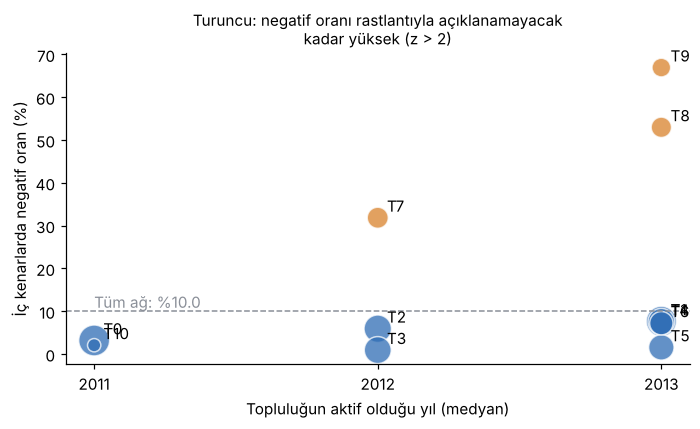

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 4))
d = tt[tt["ic_kenar"] >= 30]
sc = ax.scatter(d["medyan_yil"], d["ic_neg_oran"] * 100, s=np.sqrt(d["uye"]) * 12,
                c=np.where(d["neg_z"] > 2, TURUNCU, MAVI), alpha=0.75, edgecolor="white")
ax.axhline(neg_oran * 100, color=GRI, ls="--", lw=1)
ax.text(d["medyan_yil"].min(), neg_oran * 100 + 0.8, f"Tüm ağ: %{neg_oran*100:.1f}", color=GRI)
for c, r in d.iterrows():
    ax.annotate(f"T{c}", (r.medyan_yil, r.ic_neg_oran * 100), xytext=(6, 4), textcoords="offset points")
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Topluluğun aktif olduğu yıl (medyan)"); ax.set_ylabel("İç kenarlarda negatif oran (%)")
ax.set_title("Turuncu: negatif oranı rastlantıyla açıklanamayacak\nkadar yüksek (z > 2)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "topluluk_negatif.png", dpi=200); plt.show()

### 6.3 "−−−" üçgenleri nerede? ve güçlü bileşenin dışında kim var?

In [18]:
eksi3 = {"toplam": 0, "tek_toplulukta": 0, "T9_icinde": 0}
for a in range(len(s_nodes)):
    for b in adj[a]:
        if b <= a: continue
        for c in adj[a] & adj[b]:
            if c <= b: continue
            if isaret[eidx[(a, b)]] < 0 and isaret[eidx[(a, c)]] < 0 and isaret[eidx[(b, c)]] < 0:
                ks = {uye[s_nodes[a]], uye[s_nodes[b]], uye[s_nodes[c]]}
                eksi3["toplam"] += 1
                eksi3["tek_toplulukta"] += len(ks) == 1
                eksi3["T9_icinde"] += ks == {9}
scc_buyuk = max(scc, key=len)
disari = [v for v in G if v not in scc_buyuk]
ozet["eksi3_ucgen"] = eksi3
ozet["guclu_bilesen_disi"] = {"dugum": len(disari),
                              "hic_puan_vermemis": sum(1 for v in disari if G.out_degree(v) == 0),
                              "hic_puan_almamis": sum(1 for v in disari if G.in_degree(v) == 0)}
eksi3, ozet["guclu_bilesen_disi"]

({'toplam': 326, 'tek_toplulukta': 54, 'T9_icinde': 10},
 {'dugum': 1172, 'hic_puan_vermemis': 1067, 'hic_puan_almamis': 23})

## 7. Null model: 100 derece korumalı rastgele ağ

In [19]:
deg_seq = gUall.degree()
null = {"kumelenme": [], "ort_yol": [], "modularite": []}
for i in range(100):
    random.seed(SEED + i)
    r = ig.Graph.Degree_Sequence(deg_seq, method="edge_switching_simple")
    comps = r.connected_components(); rl = comps.giant()
    null["kumelenme"].append(r.transitivity_avglocal_undirected(mode="zero"))
    null["ort_yol"].append(rl.average_path_length(directed=False))
    null["modularite"].append(r.community_multilevel().modularity)

# Adil karşılaştırma: modülerlik her iki tarafta da aynı algoritmayla (Louvain) ölçülür.
gozlenen = {"kumelenme": gUall.transitivity_avglocal_undirected(mode="zero"),
            "ort_yol": ort_yol, "modularite": kararlilik["louvain_modularite_ort"]}
nm = {}
for k in null:
    a = np.array(null[k])
    nm[k] = {"gozlenen": float(gozlenen[k]), "null_ort": float(a.mean()), "null_std": float(a.std()),
             "z": float((gozlenen[k] - a.mean()) / a.std())}
ozet["null_model"] = nm
pd.DataFrame(nm).T.round(4)

,gozlenen,null_ort,null_std,z
kumelenme,0.1775,0.0740,0.0018,56.9306
ort_yol,3.5711,3.4962,0.0073,10.2780
modularite,0.4889,0.3097,0.0009,191.9060


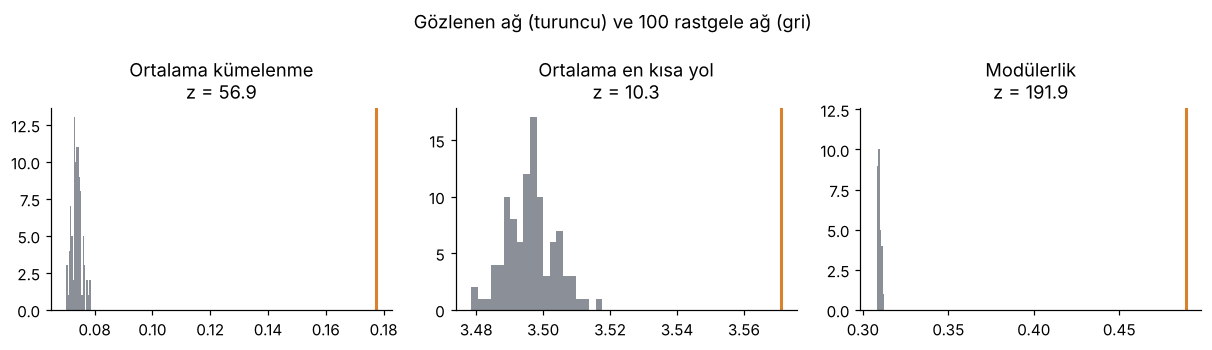

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (k, baslik) in zip(axes, [("kumelenme", "Ortalama kümelenme"), ("ort_yol", "Ortalama en kısa yol"), ("modularite", "Modülerlik")]):
    ax.hist(null[k], bins=20, color=GRI)
    ax.axvline(gozlenen[k], color=TURUNCU, lw=2)
    ax.set_title(f"{baslik}\nz = {nm[k]['z']:.1f}")
fig.suptitle("Gözlenen ağ (turuncu) ve 100 rastgele ağ (gri)")
fig.tight_layout(); fig.savefig(FIG / "null_model.png", dpi=200); plt.show()

## 8. Sonuçları kaydet

In [21]:
mer.to_csv(RES / "dugum_olculeri.csv")
tt.to_csv(RES / "topluluklar.csv")
with open(RES / "ozet.json", "w", encoding="utf-8") as f:
    json.dump(ozet, f, ensure_ascii=False, indent=2, default=float)
print("Kaydedildi.")

Kaydedildi.
